train.csv — дома с известной ценой. На них можно изучать данные, обучать и проверять модели.
test.csv — дома без SalePrice. Их предсказания нужно отправить на Kaggle.
data_description.txt — расшифровка признаков и их значений.
sample_submission.csv — пример файла для отправки: столбцы Id и SalePrice.



EDA + Эксперименты

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
train.shape, test.shape

((1460, 81), (1459, 80))

In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [6]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [3]:
missing = pd.DataFrame({
    'train_count': train.isna().sum(),
    'train_percent': train.isna().mean() * 100,
    'test_count': test.isna().sum(),
    'test_percent': test.isna().mean() * 100,
})
missing.round(2)

,train_count,train_percent,test_count,test_percent
1stFlrSF,0,0.00,0.0,0.00
2ndFlrSF,0,0.00,0.0,0.00
3SsnPorch,0,0.00,0.0,0.00
Alley,1369,93.77,1352.0,92.67
BedroomAbvGr,0,0.00,0.0,0.00
...,...,...,...,...
Utilities,0,0.00,2.0,0.14
WoodDeckSF,0,0.00,0.0,0.00
YearBuilt,0,0.00,0.0,0.00
YearRemodAdd,0,0.00,0.0,0.00


In [4]:
# Есть хотя бы один пропуск в трейне или тесте по фичам
missing = missing[
    (missing['train_count'] > 0) | (missing['test_count'] > 0)
]

missing.round(2)

,train_count,train_percent,test_count,test_percent
Alley,1369,93.77,1352.0,92.67
BsmtCond,37,2.53,45.0,3.08
BsmtExposure,38,2.60,44.0,3.02
BsmtFinSF1,0,0.00,1.0,0.07
BsmtFinSF2,0,0.00,1.0,0.07
BsmtFinType1,37,2.53,42.0,2.88
BsmtFinType2,38,2.60,42.0,2.88
BsmtFullBath,0,0.00,2.0,0.14
BsmtHalfBath,0,0.00,2.0,0.14
BsmtQual,37,2.53,44.0,3.02


In [9]:
# Проверка по двум признакам не случайны ли совпадение в кол-во пропусков. 
# Реальны - нет гаража
(train['GarageQual'].isna() != train['GarageType'].isna()).sum()

np.int64(0)

In [10]:
train.loc[
    train['FireplaceQu'].isna(),
    ['FireplaceQu', 'Fireplaces']
].drop_duplicates()

,FireplaceQu,Fireplaces
0,NaN,0


у всех домов с пропуском в FireplaceQu количество каминов равно нулю.

In [11]:
train.loc[
    train['BsmtQual'].isna(),
    ['BsmtQual', 'TotalBsmtSF']
].drop_duplicates()

,BsmtQual,TotalBsmtSF
17,NaN,0


In [12]:
train['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

(array([148., 723., 373., 135.,  51.,  19.,   4.,   3.,   2.,   2.]),
 array([ 34900., 106910., 178920., 250930., 322940., 394950., 466960.,
        538970., 610980., 682990., 755000.]),
 <BarContainer object of 10 artists>)

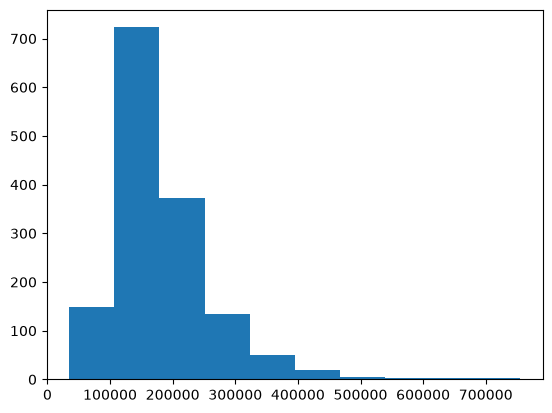

In [13]:
plt.hist(train['SalePrice'])

Большинство домов в разрезе 100-200 тыс. Хвост тянется до 750 тыс+ домов. Поэтому среднее выше 50% перцентиля

(array([  5.,  12.,  54., 184., 470., 400., 220.,  90.,  19.,   6.]),
 array([10.46027076, 10.76769112, 11.07511148, 11.38253184, 11.6899522 ,
        11.99737256, 12.30479292, 12.61221328, 12.91963363, 13.22705399,
        13.53447435]),
 <BarContainer object of 10 artists>)

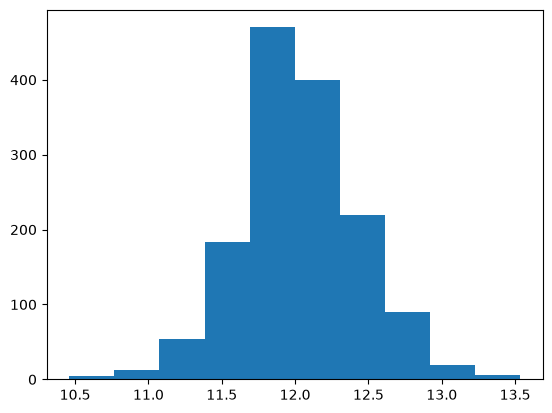

In [14]:
plt.hist(np.log1p(train['SalePrice']))

исходная цена имеет правый хвост, а после логарифмирования распределение стало более симметричным. В каггле метрика по логарифму оценивается


In [15]:
train.dtypes.value_counts()

str        43
int64      35
float64     3
Name: count, dtype: int64

In [16]:
train.select_dtypes(include='number').columns


Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='str')

In [17]:
train['YearBuilt']

0       2003
1       1976
2       2001
3       1915
4       2000
        ... 
1455    1999
1456    1978
1457    1941
1458    1950
1459    1965
Name: YearBuilt, Length: 1460, dtype: int64

In [18]:
train['MoSold']

0        2
1        5
2        9
3        2
4       12
        ..
1455     8
1456     2
1457     5
1458     4
1459     6
Name: MoSold, Length: 1460, dtype: int64

In [19]:
train.select_dtypes(include='str').nunique().sort_values()


Street            2
Alley             2
Utilities         2
CentralAir        2
MasVnrType        3
LandSlope         3
PavedDrive        3
GarageFinish      3
PoolQC            3
ExterQual         4
BsmtQual          4
BsmtExposure      4
BsmtCond          4
KitchenQual       4
LandContour       4
LotShape          4
Fence             4
MiscFeature       4
ExterCond         5
Electrical        5
HeatingQC         5
BldgType          5
MSZoning          5
LotConfig         5
GarageQual        5
GarageCond        5
FireplaceQu       5
Heating           6
BsmtFinType1      6
BsmtFinType2      6
RoofStyle         6
Foundation        6
GarageType        6
SaleCondition     6
Functional        7
HouseStyle        8
RoofMatl          8
Condition2        8
SaleType          9
Condition1        9
Exterior1st      15
Exterior2nd      16
Neighborhood     25
dtype: int64

In [20]:
train['Utilities'].value_counts()

Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

In [21]:
test['Utilities'].value_counts(dropna=False)

Utilities
AllPub    1457
NaN          2
Name: count, dtype: int64

Utilities все значение кроме одного одинаковые, 2 пропуска. На такой выборке можно будет убрать из фичей


In [22]:
train['Neighborhood'].value_counts()

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
StoneBr     25
SWISU       25
MeadowV     17
Blmngtn     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

In [23]:
round(train.groupby('Neighborhood')['SalePrice'].median(),2)

Neighborhood
Blmngtn    191000.0
Blueste    137500.0
BrDale     106000.0
BrkSide    124300.0
ClearCr    200250.0
CollgCr    197200.0
Crawfor    200624.0
Edwards    121750.0
Gilbert    181000.0
IDOTRR     103000.0
MeadowV     88000.0
Mitchel    153500.0
NAmes      140000.0
NPkVill    146000.0
NWAmes     182900.0
NoRidge    301500.0
NridgHt    315000.0
OldTown    119000.0
SWISU      139500.0
Sawyer     135000.0
SawyerW    179900.0
Somerst    225500.0
StoneBr    278000.0
Timber     228475.0
Veenker    218000.0
Name: SalePrice, dtype: float64

In [24]:
train['GrLivArea'].corr(train['SalePrice'])

np.float64(0.7086244776126521)

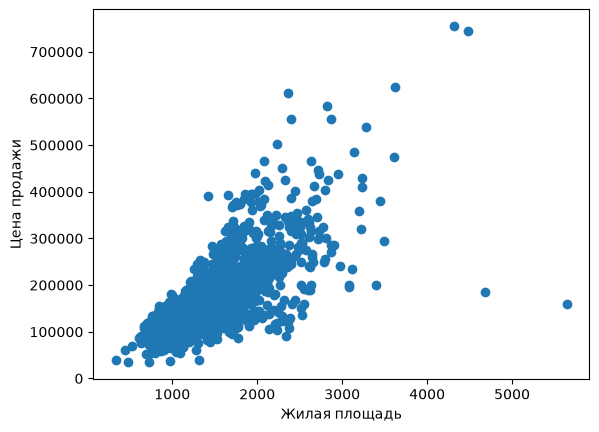

In [25]:
plt.scatter(train['GrLivArea'], train['SalePrice'])
plt.xlabel('Жилая площадь')
plt.ylabel('Цена продажи')
plt.show()

Площадь и цена созависимы. Также есть зависимость от района дома

In [26]:
train.select_dtypes(include='number').corr()['SalePrice'].sort_values(ascending=False)


SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

In [27]:
train['GarageCars'].corr(train['GarageArea'])

np.float64(0.8824754142814627)

In [5]:
features = train.drop(columns=['SalePrice','Id'])

In [6]:
X = features.copy()
y = train['SalePrice']

In [30]:
X.shape

(1460, 79)

In [7]:
numeric_features = X.select_dtypes(include='number').columns
categorical_features = X.select_dtypes(include='str').columns

In [32]:
#Разделяем фичи на числовые и категориальные. Пока не удаляем в нумерик те, что означают уже какую то категорию заранее разделенную. 

In [34]:
len(numeric_features), len(categorical_features)

(36, 43)

In [8]:
from sklearn.impute import SimpleImputer
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

In [9]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [10]:
categorical_pipeline = Pipeline([
    ("imputer", categorical_imputer),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

In [11]:
numeric_pipeline = Pipeline([
    ("imputer", numeric_imputer),
    ("scaler", StandardScaler()),
])

In [12]:
from sklearn.compose import ColumnTransformer

In [13]:
preprocessor = ColumnTransformer([
    ("numbers", numeric_pipeline, numeric_features),
    ("categories", categorical_pipeline, categorical_features),
])

In [14]:
from sklearn.linear_model import Ridge

In [15]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

In [16]:
from sklearn.model_selection import KFold, cross_val_score
import numpy as np

y_log = np.log(y)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    model,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_scores = -scores

print('RMSE по фолдам:', rmse_scores)
print('Средний RMSE:', rmse_scores.mean())
print('Стандартное отклонение:', rmse_scores.std())

RMSE по фолдам: [0.13164199 0.12894876 0.22935982 0.13414064 0.11898289]
Средний RMSE: 0.14861481782437633
Стандартное отклонение: 0.04069923523027526


Тут на одном фолде большое отклонение rmse, скорее всего из-за выбросов по цене дома некоторых попали

In [44]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'regressor__alpha': [0.1, 1, 10, 100]
}

grid = GridSearchCV(
    model,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

grid.fit(X, y_log)

print('Лучший alpha:', grid.best_params_)
print('Средний RMSE:', -grid.best_score_)

Лучший alpha: {'regressor__alpha': 10}
Средний RMSE: 0.1467840986122884


In [45]:
results = pd.DataFrame(grid.cv_results_)

results[[
    'param_regressor__alpha',
    'split0_test_score',
    'split1_test_score',
    'split2_test_score',
    'split3_test_score',
    'split4_test_score',
    'mean_test_score'
]]

,param_regressor__alpha,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score
0,0.1,-0.127688,-0.124894,-0.239469,-0.147121,-0.114652,-0.150765
1,1.0,-0.131642,-0.128949,-0.229360,-0.134141,-0.118983,-0.148615
2,10.0,-0.136104,-0.129376,-0.224394,-0.127705,-0.116342,-0.146784
3,100.0,-0.140849,-0.125964,-0.224208,-0.129130,-0.116052,-0.147241


In [48]:
results_table = pd.DataFrame([
    {
        'Модель': 'Ridge',
        'Обработка категорий': 'Самое частое значение',
        'alpha': 10,
        'Средний RMSE': -grid.best_score_
    }
])

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784


In [21]:
categorical_pipeline_missing = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor_missing = ColumnTransformer([
    ('numbers', numeric_pipeline, numeric_features),
    ('categories', categorical_pipeline_missing, categorical_features),
])

model_missing = Pipeline([
    ('preprocessor', preprocessor_missing),
    ('regressor', Ridge(alpha=10)),
])

In [50]:
scores_missing = cross_val_score(
    model_missing,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_missing = -scores_missing

print('RMSE по фолдам:', rmse_missing)
print('Средний RMSE:', rmse_missing.mean())

RMSE по фолдам: [0.1364864  0.12975185 0.22470019 0.12783142 0.115441  ]
Средний RMSE: 0.14684217237708191


In [51]:
results_table.loc[len(results_table)] = {
    'Модель': 'Ridge',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': 10,
    'Средний RMSE': rmse_missing.mean()
}

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842


In [52]:
from sklearn.tree import DecisionTreeRegressor

In [53]:
model_tree = Pipeline([
    ("preprocessor", preprocessor_missing),
    ("regressor", DecisionTreeRegressor(max_depth=5,random_state=42)),
])

In [54]:
scores_tree = cross_val_score(
    model_tree,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_tree = -scores_tree

print('RMSE по фолдам:', rmse_tree)
print('Средний RMSE:', rmse_tree.mean())


RMSE по фолдам: [0.20378504 0.18721119 0.21088649 0.19531884 0.18934164]
Средний RMSE: 0.19730863919582903


In [55]:
results_table.loc[len(results_table)] = {
    'Модель': 'DecisionTree',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': rmse_tree.mean()
}

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842
2,DecisionTree,Отдельная категория Missing,None,0.197309


In [56]:
from sklearn.ensemble import RandomForestRegressor

In [57]:
model_random_forest = Pipeline([
    ("preprocessor", preprocessor_missing),
    ("regressor", RandomForestRegressor(n_estimators=200,random_state=42, n_jobs=-1)),
])

In [58]:
scores_random_forest = cross_val_score(
    model_random_forest,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_random_forest = -scores_random_forest

print('RMSE по фолдам:', rmse_random_forest)
print('Средний RMSE:', rmse_random_forest.mean())


RMSE по фолдам: [0.14607148 0.12755795 0.17678391 0.14923192 0.12263091]
Средний RMSE: 0.14445523462285437


In [59]:
results_table.loc[len(results_table)] = {
    'Модель': 'RandomForest',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': rmse_random_forest.mean()
}

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842
2,DecisionTree,Отдельная категория Missing,None,0.197309
3,RandomForest,Отдельная категория Missing,None,0.144455


In [60]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'regressor__max_depth': [3, 5, 7, 10, 15, None],
    'regressor__min_samples_leaf': [1, 2, 5, 10, 20]
}

grid_forest = GridSearchCV(
    model_random_forest,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

grid_forest.fit(X, y_log)

print('Лучший :', grid.best_params_) # Ошибся, параметры не передал из гридсерча новые в вывод
print('Средний RMSE:', -grid.best_score_)

Лучший : {'regressor__alpha': 10}
Средний RMSE: 0.1467840986122884


In [61]:
print('Лучшие параметры:', grid_forest.best_params_)
print('Средний RMSE:', -grid_forest.best_score_)

Лучшие параметры: {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1}
Средний RMSE: 0.14445523462285442


По итогу тут GridSearch улучшения не дал. Глубина деревьев и мин. размер листа не меняют результат. В таблицу не добавляю


In [62]:
results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842
2,DecisionTree,Отдельная категория Missing,None,0.197309
3,RandomForest,Отдельная категория Missing,None,0.144455


In [64]:
X_cat = X.copy()

In [65]:
X_cat[categorical_features] = (
    X_cat[categorical_features]
    .fillna('Missing')
)

In [67]:
X_cat[categorical_features].isna().sum().sum()

np.int64(0)

In [71]:
from catboost import CatBoostRegressor

model_catboost = CatBoostRegressor(
    iterations=500,
    learning_rate=0.03,
    depth=4,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)


In [72]:
scores_catboost = cross_val_score(
    model_catboost,
    X_cat,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    params={'cat_features': list(categorical_features)}
)

rmse_catboost = -scores_catboost

print('RMSE по фолдам:', rmse_catboost)
print('Средний RMSE:', rmse_catboost.mean())

RMSE по фолдам: [0.13573932 0.11809966 0.15685671 0.13597675 0.11298985]
Средний RMSE: 0.1319324609821983


In [73]:
results_table.loc[len(results_table)] = {
    'Модель': 'CatBoost',
    'Обработка категорий': 'Категории CatBoost, пропуски Missing',
    'alpha': None,
    'Средний RMSE': rmse_catboost.mean()
}

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842
2,DecisionTree,Отдельная категория Missing,None,0.197309
3,RandomForest,Отдельная категория Missing,None,0.144455
4,CatBoost,"Категории CatBoost, пропуски Missing",None,0.131932


Пока лучший результат catboost


In [74]:
from sklearn.model_selection import GridSearchCV

param_grid_catboost = {
    'depth': [4, 6],
    'learning_rate': [0.03, 0.1]
}

grid_catboost = GridSearchCV(
    model_catboost,
    param_grid=param_grid_catboost,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

grid_catboost.fit(X_cat, y_log, cat_features=list(categorical_features))

print('Лучшие параметры:', grid_catboost.best_params_) 
print('Средний RMSE:', -grid_catboost.best_score_)

Лучшие параметры: {'depth': 4, 'learning_rate': 0.1}
Средний RMSE: 0.12765363825992182


In [75]:
results_table.loc[len(results_table)] = {
    'Модель': 'CatBoost (GridSearch)',
    'Обработка категорий': 'Категории CatBoost, пропуски Missing',
    'alpha': None,
    'Средний RMSE': -grid_catboost.best_score_
}

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842
2,DecisionTree,Отдельная категория Missing,None,0.197309
3,RandomForest,Отдельная категория Missing,None,0.144455
4,CatBoost,"Категории CatBoost, пропуски Missing",None,0.131932
5,CatBoost (GridSearch),"Категории CatBoost, пропуски Missing",None,0.127654


In [ ]:
results = pd.DataFrame(grid.cv_results_)

results[[
    'param_regressor__alpha',
    'split0_test_score',
    'split1_test_score',
    'split2_test_score',
    'split3_test_score',
    'split4_test_score',
    'mean_test_score'
]]

,param_depth,param_learning_rate,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score
0,4,0.03,-0.135739,-0.118100,-0.156857,-0.135977,-0.112990,-0.131932
1,4,0.10,-0.135102,-0.113718,-0.158344,-0.123308,-0.107796,-0.127654
2,6,0.03,-0.132041,-0.116703,-0.152643,-0.136166,-0.112719,-0.130054
3,6,0.10,-0.132245,-0.115736,-0.160111,-0.127791,-0.107834,-0.128743


In [ ]:
from sklearn.linear_model import Lasso

In [78]:
model_lasso = Pipeline([
    ('preprocessor', preprocessor_missing),
    ('regressor', Lasso(alpha=0.001, max_iter=10000))
])

In [79]:
scores_lasso = cross_val_score(
    model_lasso,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_scores_lasso = -scores_lasso

print('RMSE по фолдам:', rmse_scores_lasso)
print('Средний RMSE:', rmse_scores_lasso.mean())
print('Стандартное отклонение:', rmse_scores_lasso.std())

RMSE по фолдам: [0.13777677 0.12553028 0.22896374 0.11975989 0.1115061 ]
Средний RMSE: 0.14470735553637698
Стандартное отклонение: 0.0429875102246537


In [80]:
results_table.loc[len(results_table)] = {
    'Модель': 'Lasso',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': 0.001,
    'Средний RMSE': rmse_scores.mean()
}

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842
2,DecisionTree,Отдельная категория Missing,None,0.197309
3,RandomForest,Отдельная категория Missing,None,0.144455
4,CatBoost,"Категории CatBoost, пропуски Missing",None,0.131932
5,CatBoost (GridSearch),"Категории CatBoost, пропуски Missing",None,0.127654
6,Lasso,Отдельная категория Missing,0.001,0.148615


In [81]:
param_grid_lasso = {
    'regressor__alpha': [0.0001, 0.0005, 0.001, 0.005, 0.01]
}

grid_lasso = GridSearchCV(
    model_lasso,
    param_grid=param_grid_lasso,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

grid_lasso.fit(X, y_log)

print('Лучший alpha:', grid_lasso.best_params_)
print('Средний RMSE:', -grid_lasso.best_score_)

Лучший alpha: {'regressor__alpha': 0.0005}
Средний RMSE: 0.1416315083418303


In [82]:
results_table.loc[len(results_table)] = {
    'Модель': 'Lasso (GridSearch)',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': 0.0005,
    'Средний RMSE': -grid_lasso.best_score_
}

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842
2,DecisionTree,Отдельная категория Missing,None,0.197309
3,RandomForest,Отдельная категория Missing,None,0.144455
4,CatBoost,"Категории CatBoost, пропуски Missing",None,0.131932
5,CatBoost (GridSearch),"Категории CatBoost, пропуски Missing",None,0.127654
6,Lasso,Отдельная категория Missing,0.001,0.148615
7,Lasso (GridSearch),Отдельная категория Missing,0.0005,0.141632


In [83]:
from sklearn.linear_model import ElasticNet

In [84]:
model_elasticnet = Pipeline([
    ('preprocessor', preprocessor_missing),
    ('regressor', ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000))
])

In [85]:
scores_elasticnet = cross_val_score(
    model_elasticnet,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_scores_elasticnet = -scores_elasticnet

print('RMSE по фолдам:', rmse_scores_elasticnet)
print('Средний RMSE:', rmse_scores_elasticnet.mean())
print('Стандартное отклонение:', rmse_scores_elasticnet.std())

RMSE по фолдам: [0.13289768 0.12656606 0.22687012 0.12074392 0.11135721]
Средний RMSE: 0.1436869973934685
Стандартное отклонение: 0.04219139278432368


In [86]:
results_table.loc[len(results_table)] = {
    'Модель': 'ElasticNet',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': 0.001,
    'Средний RMSE': rmse_scores_elasticnet.mean()
}

In [87]:
param_grid_elasticnet = {
    'regressor__alpha': [0.0001, 0.0005, 0.001, 0.005, 0.01], 'regressor__l1_ratio' : [0.2, 0.5, 0.8,  1,0]
}

grid_elasticnet = GridSearchCV(
    model_elasticnet,
    param_grid=param_grid_elasticnet,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

grid_elasticnet.fit(X, y_log)

print('Лучший alpha:', grid_elasticnet.best_params_)
print('Средний RMSE:', -grid_elasticnet.best_score_)

Лучший alpha: {'regressor__alpha': 0.0005, 'regressor__l1_ratio': 1}
Средний RMSE: 0.1416315083418303


In [88]:
from sklearn.svm import SVR

In [89]:
model_SVR = Pipeline([
    ('preprocessor', preprocessor_missing),
    ('regressor', SVR())
])

In [90]:
scores_SVR = cross_val_score(
    model_SVR,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_scores_SVR = -scores_SVR

print('RMSE по фолдам:', rmse_scores_SVR)
print('Средний RMSE:', rmse_scores_SVR.mean())
print('Стандартное отклонение:', rmse_scores_SVR.std())

RMSE по фолдам: [0.15173658 0.15609821 0.13396389 0.15366106 0.1224373 ]
Средний RMSE: 0.14357940791617646
Стандартное отклонение: 0.013147977569361534


In [91]:
results_table.loc[len(results_table)] = {
    'Модель': 'SVR',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': rmse_scores_SVR.mean()
}

In [92]:
param_grid_SVR = {
    'regressor__C': [0.1, 1, 10],
    'regressor__epsilon': [0.01, 0.1, 0.2]
}

grid_SVR = GridSearchCV(
    model_SVR,
    param_grid=param_grid_SVR,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

grid_SVR.fit(X, y_log)

print('Лучший alpha:', grid_SVR.best_params_)
print('Средний RMSE:', -grid_SVR.best_score_)

Лучший alpha: {'regressor__C': 1, 'regressor__epsilon': 0.01}
Средний RMSE: 0.13779607376357533


In [93]:
results_table.loc[len(results_table)] = {
    'Модель': 'SVR (GridSearch)',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': -grid_SVR.best_score_
}

In [94]:
from sklearn.neighbors import KNeighborsRegressor

In [95]:
model_KNR = Pipeline([
    ('preprocessor', preprocessor_missing),
    ('regressor', KNeighborsRegressor())
])

In [96]:
scores_KNR = cross_val_score(
    model_KNR,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_scores_KNR = -scores_KNR

print('RMSE по фолдам:', rmse_scores_KNR)
print('Средний RMSE:', rmse_scores_KNR.mean())
print('Стандартное отклонение:', rmse_scores_KNR.std())

RMSE по фолдам: [0.18476186 0.18195967 0.17621597 0.18934747 0.1500507 ]
Средний RMSE: 0.17646713395515246
Стандартное отклонение: 0.01387634373851624


In [97]:
results_table.loc[len(results_table)] = {
    'Модель': 'KNN',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': rmse_scores_KNR.mean()
}

In [98]:
param_grid_KNR = {
    'regressor__n_neighbors': [3, 5, 10, 20],
    'regressor__weights': ['uniform', 'distance']
}

grid_KNR = GridSearchCV(
    model_KNR,
    param_grid=param_grid_KNR,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

grid_KNR.fit(X, y_log)

print('Лучшие параметры:', grid_KNR.best_params_)
print('Средний RMSE:', -grid_KNR.best_score_)

Лучшие параметры: {'regressor__n_neighbors': 10, 'regressor__weights': 'distance'}
Средний RMSE: 0.172004231613479


In [99]:
results_table.loc[len(results_table)] = {
    'Модель': 'KNN (GridSearch)',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': -grid_KNR.best_score_
}

In [100]:
import optuna

In [101]:
def objective(trial):
    depth = trial.suggest_int('depth', 3, 8)
    learning_rate = trial.suggest_float('learning_rate', 0.01, 0.2, log=True)
    l2_leaf_reg = trial.suggest_float('l2_leaf_reg', 1, 10, log=True)

    model_trial = CatBoostRegressor(
        iterations=500,
        depth=depth,
        learning_rate=learning_rate,
        l2_leaf_reg=l2_leaf_reg,
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )

    scores = cross_val_score(
        model_trial,
        X_cat,
        y_log,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        params={'cat_features': list(categorical_features)}
    )

    return -scores.mean()

In [102]:
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=20)

print('Лучшие параметры:', study.best_params)
print('Средний RMSE:', study.best_value)

[I 2026-11-24 23:23:30,114] A new study created in memory with name: no-name-80457d74-6f52-4822-8898-ed0bd9eda08b
[I 2026-11-24 23:24:43,524] Trial 0 finished with value: 0.12719242799650732 and parameters: {'depth': 5, 'learning_rate': 0.17254716573280354, 'l2_leaf_reg': 5.395030966670228}. Best is trial 0 with value: 0.12719242799650732.
[I 2026-11-24 23:26:15,081] Trial 1 finished with value: 0.13182075186963355 and parameters: {'depth': 6, 'learning_rate': 0.015958237752949748, 'l2_leaf_reg': 1.4321698289111515}. Best is trial 0 with value: 0.12719242799650732.
[I 2026-11-24 23:26:53,643] Trial 2 finished with value: 0.13054156541587247 and parameters: {'depth': 3, 'learning_rate': 0.13394334706750485, 'l2_leaf_reg': 3.9913058785616786}. Best is trial 0 with value: 0.12719242799650732.
[I 2026-11-24 23:28:49,305] Trial 3 finished with value: 0.14466070809150205 and parameters: {'depth': 7, 'learning_rate': 0.010636066512540286, 'l2_leaf_reg': 9.330606024425668}. Best is trial 0 wit

KeyboardInterrupt: 

In [103]:
print('Завершённых попыток:', len(study.trials))
print('Лучшие параметры:', study.best_params)
print('Средний RMSE:', study.best_value)

Завершённых попыток: 6
Лучшие параметры: {'depth': 5, 'learning_rate': 0.17254716573280354, 'l2_leaf_reg': 5.395030966670228}
Средний RMSE: 0.12719242799650732


In [104]:
from optuna.trial import TrialState

completed_trials = study.get_trials(states=[TrialState.COMPLETE])
print('Успешно завершённых попыток:', len(completed_trials))

Успешно завершённых попыток: 5


In [105]:
results_table.loc[len(results_table)] = {
    'Модель': 'CatBoost (Optuna)',
    'Обработка категорий': 'Категории CatBoost, пропуски Missing',
    'alpha': None,
    'Средний RMSE': study.best_value
}

In [106]:
results_table.sort_values('Средний RMSE')

,Модель,Обработка категорий,alpha,Средний RMSE
13,CatBoost (Optuna),"Категории CatBoost, пропуски Missing",None,0.127192
5,CatBoost (GridSearch),"Категории CatBoost, пропуски Missing",None,0.127654
4,CatBoost,"Категории CatBoost, пропуски Missing",None,0.131932
10,SVR (GridSearch),Отдельная категория Missing,None,0.137796
7,Lasso (GridSearch),Отдельная категория Missing,0.0005,0.141632
9,SVR,Отдельная категория Missing,None,0.143579
8,ElasticNet,Отдельная категория Missing,0.001,0.143687
3,RandomForest,Отдельная категория Missing,None,0.144455
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842


In [107]:
rmse_scores_lasso.mean()

np.float64(0.14470735553637698)

In [108]:
results_table.loc[6, 'Средний RMSE'] = rmse_scores_lasso.mean()

In [109]:
results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10,0.146784
1,Ridge,Отдельная категория Missing,10,0.146842
2,DecisionTree,Отдельная категория Missing,None,0.197309
3,RandomForest,Отдельная категория Missing,None,0.144455
4,CatBoost,"Категории CatBoost, пропуски Missing",None,0.131932
5,CatBoost (GridSearch),"Категории CatBoost, пропуски Missing",None,0.127654
6,Lasso,Отдельная категория Missing,0.001,0.144707
7,Lasso (GridSearch),Отдельная категория Missing,0.0005,0.141632
8,ElasticNet,Отдельная категория Missing,0.001,0.143687
9,SVR,Отдельная категория Missing,None,0.143579


In [110]:
from sklearn.ensemble import GradientBoostingRegressor

In [111]:
model_boosting = Pipeline([
    ('preprocessor', preprocessor_missing),
    ('regressor', GradientBoostingRegressor(random_state=42))
])

In [112]:
scores_boosting = cross_val_score(
    model_boosting,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_scores_boosting = -scores_boosting

print('RMSE по фолдам:', rmse_scores_boosting)
print('Средний RMSE:', rmse_scores_boosting.mean())
print('Стандартное отклонение:', rmse_scores_boosting.std())

RMSE по фолдам: [0.13385449 0.11390351 0.16913287 0.13571269 0.11444512]
Средний RMSE: 0.1334097355569616
Стандартное отклонение: 0.02010866958133295


In [113]:
results_table.loc[len(results_table)] = {
    'Модель': 'GradientBoosting',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': rmse_scores_boosting.mean()
}

In [114]:
param_grid_boosting = {
    'regressor__n_estimators': [100, 300],
    'regressor__learning_rate': [0.03, 0.1],
    'regressor__max_depth': [2, 3]
}

grid_boosting = GridSearchCV(
    model_boosting,
    param_grid=param_grid_boosting,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

grid_boosting.fit(X, y_log)

print('Лучшие параметры:', grid_boosting.best_params_)
print('Средний RMSE:', -grid_boosting.best_score_)

Лучшие параметры: {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__n_estimators': 300}
Средний RMSE: 0.13078738430456086


In [115]:
results_table.loc[len(results_table)] = {
    'Модель': 'GradientBoosting (GridSearch)',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': -grid_boosting.best_score_
}

In [116]:
test_ids = test['Id'].copy()

X_test_cat = test.drop(columns=['Id']).copy()
X_test_cat[categorical_features] = (
    X_test_cat[categorical_features].fillna('Missing')
)

In [117]:
final_catboost = CatBoostRegressor(
    iterations=500,
    depth=5,
    learning_rate=0.17254716573280354,
    l2_leaf_reg=5.395030966670228,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

final_catboost.fit(
    X_cat,
    y_log,
    cat_features=list(categorical_features)
)

CatBoostRegressor(allow_writing_files=False, depth=5, iterations=500, l2_leaf_reg=5.395030966670228, learning_rate=0.17254716573280354, loss_function='RMSE', random_seed=42, verbose=False)

In [118]:
predictions_log = final_catboost.predict(X_test_cat)
predictions = np.exp(predictions_log)

In [119]:
submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': predictions
})

submission.head()

,Id,SalePrice
0,1461,110808.224487
1,1462,161083.259622
2,1463,190147.294367
3,1464,205970.252705
4,1465,184687.958991


In [120]:
submission.to_csv('submission.csv', index=False)

In [17]:
print(X.shape, y.shape)
print(len(numeric_features), len(categorical_features))

(1460, 79) (1460,)
36 43


In [18]:
from sklearn.neural_network import MLPRegressor

In [22]:
model_mlp = Pipeline([
    ('preprocessor', preprocessor_missing),
    ('regressor', MLPRegressor(hidden_layer_sizes=(64, 32),
    max_iter=500,
    random_state=42))
])


In [24]:
from sklearn.model_selection import cross_validate

mlp_cv = cross_validate(
    model_mlp,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    return_estimator=True
)

In [25]:
for i, pipeline in enumerate(mlp_cv['estimator'], start=1):
    mlp = pipeline.named_steps['regressor']
    print(f'Фолд {i}: {mlp.n_iter_} итераций, loss = {mlp.loss_:.4f}')

Фолд 1: 104 итераций, loss = 0.0064
Фолд 2: 110 итераций, loss = 0.0061
Фолд 3: 101 итераций, loss = 0.0064
Фолд 4: 102 итераций, loss = 0.0061
Фолд 5: 111 итераций, loss = 0.0058


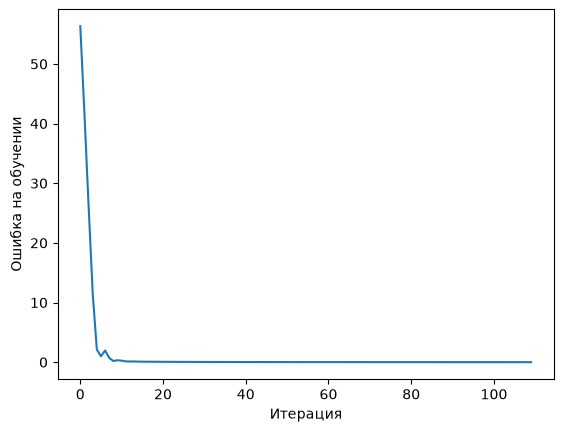

In [26]:
mlp_fold_2 = mlp_cv['estimator'][1].named_steps['regressor']

plt.plot(mlp_fold_2.loss_curve_)
plt.xlabel('Итерация')
plt.ylabel('Ошибка на обучении')
plt.show()

In [27]:
model_mlp_early = Pipeline([
    ('preprocessor', preprocessor_missing),
    ('regressor', MLPRegressor(
        hidden_layer_sizes=(64, 32),
        max_iter=500,
        early_stopping=True,
        random_state=42
    ))
])

In [28]:
scores_mlp_early = cross_val_score(
    model_mlp_early,
    X,
    y_log,
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmse_mlp_early = -scores_mlp_early

print('RMSE по фолдам:', rmse_mlp_early)
print('Средний RMSE:', rmse_mlp_early.mean())

RMSE по фолдам: [0.16192572 0.38124932 0.37053511 0.23115953 0.16671065]
Средний RMSE: 0.26231606500826243


Плохой результат на sklearn mlpregressor
Перейдём к торчу

In [31]:
import torch

print('Версия PyTorch:', torch.__version__)
print('GPU доступен:', torch.cuda.is_available())

Версия PyTorch: 2.13.0+cu126
GPU доступен: True


In [32]:
train_idx, valid_idx = next(cv.split(X))

X_train = X.iloc[train_idx]
X_valid = X.iloc[valid_idx]
y_train = y_log.iloc[train_idx]
y_valid = y_log.iloc[valid_idx]

print('Обучение:', X_train.shape, y_train.shape)
print('Проверка:', X_valid.shape, y_valid.shape)

Обучение: (1168, 79) (1168,)
Проверка: (292, 79) (292,)


In [33]:
X_train_processed = preprocessor_missing.fit_transform(X_train)
X_valid_processed = preprocessor_missing.transform(X_valid)

print('Обучение:', X_train_processed.shape)
print('Проверка:', X_valid_processed.shape)

Обучение: (1168, 301)
Проверка: (292, 301)


In [34]:
from scipy import sparse

if sparse.issparse(X_train_processed):
    X_train_processed = X_train_processed.toarray()

if sparse.issparse(X_valid_processed):
    X_valid_processed = X_valid_processed.toarray()

In [35]:
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_valid_tensor = torch.tensor(X_valid_processed, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_valid_tensor = torch.tensor(y_valid.to_numpy(), dtype=torch.float32)

In [36]:
print(X_train_tensor.shape, y_train_tensor.shape)
print(X_valid_tensor.shape, y_valid_tensor.shape)

torch.Size([1168, 301]) torch.Size([1168])
torch.Size([292, 301]) torch.Size([292])


In [37]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

In [38]:
import torch.nn as nn

model_torch = nn.Sequential(
    nn.Linear(X_train_tensor.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

In [40]:
print(model_torch)

Sequential(
  (0): Linear(in_features=301, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)


In [41]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model_torch.parameters(),
    lr=0.001
)

In [42]:
n_epochs = 100

for epoch in range(n_epochs):
    model_torch.train()

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        predictions = model_torch(X_batch).squeeze(1)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

    model_torch.eval()

    with torch.no_grad():
        valid_predictions = model_torch(X_valid_tensor).squeeze(1)
        valid_loss = criterion(valid_predictions, y_valid_tensor)
        valid_rmse = torch.sqrt(valid_loss)

    if (epoch + 1) % 10 == 0:
        print(f'Эпоха {epoch + 1}: RMSE проверки = {valid_rmse.item():.4f}')

Эпоха 10: RMSE проверки = 0.1608
Эпоха 20: RMSE проверки = 0.1396
Эпоха 30: RMSE проверки = 0.1348
Эпоха 40: RMSE проверки = 0.1320
Эпоха 50: RMSE проверки = 0.1309
Эпоха 60: RMSE проверки = 0.1346
Эпоха 70: RMSE проверки = 0.1432
Эпоха 80: RMSE проверки = 0.1372
Эпоха 90: RMSE проверки = 0.1428
Эпоха 100: RMSE проверки = 0.1413


In [50]:
results_table = pd.DataFrame([
    ['Ridge', 'Самое частое значение', 10, 0.146785],
    ['Ridge', 'Отдельная категория Missing', 10, 0.146842],
    ['DecisionTree', 'Отдельная категория Missing', None, 0.197309],
    ['RandomForest', 'Отдельная категория Missing', None, 0.144455],
    ['CatBoost', 'Категории CatBoost, пропуски Missing', None, 0.131932],
    ['CatBoost (GridSearch)', 'Категории CatBoost, пропуски Missing', None, 0.127654],
    ['Lasso', 'Отдельная категория Missing', 0.001, 0.144707],
    ['Lasso (GridSearch)', 'Отдельная категория Missing', 0.0005, 0.141632],
    ['ElasticNet', 'Отдельная категория Missing', 0.001, 0.143687],
    ['SVR', 'Отдельная категория Missing', None, 0.143579],
    ['SVR (GridSearch)', 'Отдельная категория Missing', None, 0.137796],
    ['KNN', 'Отдельная категория Missing', None, 0.176467],
    ['KNN (GridSearch)', 'Отдельная категория Missing', None, 0.172004],
    ['CatBoost (Optuna)', 'Категории CatBoost, пропуски Missing', None, 0.127192],
    ['GradientBoosting', 'Отдельная категория Missing', None, 0.133410],
    ['GradientBoosting (GridSearch)', 'Отдельная категория Missing', None, 0.130787],
    ['PyTorch MLP (1 фолд, early stopping)', 'Отдельная категория Missing', None, 0.1295],
], columns=['Модель', 'Обработка категорий', 'alpha', 'Средний RMSE'])

results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10.0000,0.146785
1,Ridge,Отдельная категория Missing,10.0000,0.146842
2,DecisionTree,Отдельная категория Missing,NaN,0.197309
3,RandomForest,Отдельная категория Missing,NaN,0.144455
4,CatBoost,"Категории CatBoost, пропуски Missing",NaN,0.131932
5,CatBoost (GridSearch),"Категории CatBoost, пропуски Missing",NaN,0.127654
6,Lasso,Отдельная категория Missing,0.0010,0.144707
7,Lasso (GridSearch),Отдельная категория Missing,0.0005,0.141632
8,ElasticNet,Отдельная категория Missing,0.0010,0.143687
9,SVR,Отдельная категория Missing,NaN,0.143579


In [56]:
rmse_folds = []
n_epochs = 100

for fold, (train_idx, valid_idx) in enumerate(cv.split(X), start=1):
    # Разделяем данные текущего фолда
    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]
    y_train = y_log.iloc[train_idx]
    y_valid = y_log.iloc[valid_idx]

    # Обучаем обработку только на обучающей части
    X_train_processed = preprocessor_missing.fit_transform(X_train)
    X_valid_processed = preprocessor_missing.transform(X_valid)

    # При необходимости переводим разреженные матрицы в обычные массивы
    if sparse.issparse(X_train_processed):
        X_train_processed = X_train_processed.toarray()

    if sparse.issparse(X_valid_processed):
        X_valid_processed = X_valid_processed.toarray()

    # Преобразуем данные в тензоры
    X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
    X_valid_tensor = torch.tensor(X_valid_processed, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
    y_valid_tensor = torch.tensor(y_valid.to_numpy(), dtype=torch.float32)

    # Создаём батчи
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True
    )

    # Создаём новую сеть и оптимизатор для каждого фолда
    model_torch = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    )

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model_torch.parameters(), lr=0.001)

    # Обучаем сеть
    for epoch in range(n_epochs):
        model_torch.train()

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            predictions = model_torch(X_batch).squeeze(1)
            loss = criterion(predictions, y_batch)

            loss.backward()
            optimizer.step()

    # Проверяем после последней эпохи
    model_torch.eval()

    with torch.no_grad():
        valid_predictions = model_torch(X_valid_tensor).squeeze(1)
        valid_loss = criterion(valid_predictions, y_valid_tensor)
        valid_rmse = torch.sqrt(valid_loss).item()

    rmse_folds.append(valid_rmse)
    print(f'Фолд {fold}: RMSE = {valid_rmse:.4f}')

print('Средний RMSE:', np.mean(rmse_folds))
print('Стандартное отклонение:', np.std(rmse_folds))

Фолд 1: RMSE = 0.1688
Фолд 2: RMSE = 0.1683
Фолд 3: RMSE = 0.2823
Фолд 4: RMSE = 0.1493
Фолд 5: RMSE = 0.1613
Средний RMSE: 0.1860271692276001
Стандартное отклонение: 0.04864951904361058


In [57]:
results_table.loc[len(results_table)] = {
    'Модель': 'PyTorch MLP (5 фолдов, 100 эпох)',
    'Обработка категорий': 'Отдельная категория Missing',
    'alpha': None,
    'Средний RMSE': np.mean(rmse_folds)
}

In [58]:
results_table

,Модель,Обработка категорий,alpha,Средний RMSE
0,Ridge,Самое частое значение,10.0,0.146785
1,Ridge,Отдельная категория Missing,10.0,0.146842
2,DecisionTree,Отдельная категория Missing,NaN,0.197309
3,RandomForest,Отдельная категория Missing,NaN,0.144455
4,CatBoost,"Категории CatBoost, пропуски Missing",NaN,0.131932
5,CatBoost (GridSearch),"Категории CatBoost, пропуски Missing",NaN,0.127654
6,Lasso,Отдельная категория Missing,0.001,0.144707
7,Lasso (GridSearch),Отдельная категория Missing,0.0005,0.141632
8,ElasticNet,Отдельная категория Missing,0.001,0.143687
9,SVR,Отдельная категория Missing,NaN,0.143579
